# Chapter 12: Approximate Relations

Companion notebook for **Chapter 12** of *Bernoulli Types: An Algebra of Approximate Computation*. Source files: `book/chapters/ch12/`.

Chapter 12 lifts the approximate-set framework of Part II to relations. A relation $R \subseteq T \times U$ is a set of pairs; an approximate relation $\tilde R$ is a $\Bernoulli{\BoolType}$ on $T \times U$. The headline algorithmic instance is the **similarity join**: given two large relations, find all row pairs with Jaccard similarity above a threshold $\theta$, without paying the $O(|R_1||R_2|)$ exact cost.

This notebook builds the worked example from \S12.3 of the chapter:

1. **Synthetic relations** with a planted overlap structure: two relations of 1000 rows each, with 100 row pairs engineered to have $J \ge 0.5$ (similar) and the rest near-disjoint.
2. **MinHash signatures** of length $k = 200$ per row, reusing the per-index SHA-256 hash family from the chapter 10 notebook (\S3 of `ch10-sketches-estimators.ipynb`).
3. **Sampled exact Jaccard** over 10000 random row pairs as ground truth (full $10^6$-pair exact computation is what the LSH stage is trying to avoid).
4. **MinHash similarity join** on the same sample: threshold $\hat J \ge \theta$ and measure FPR and FNR against the exact ground truth.
5. **LSH bucketing** with $b = 20$ bands of $r = 10$ rows: bucket the full $1000 \times 1000$ relation and verify the candidate pair count is sub-quadratic.
6. **Precision and recall of the LSH candidate set** against the planted similar-pair ground truth.

**Conventions:**
- Hash family: per-slot SHA-256 with a deterministic salt derived from `(seed, slot_index)`, identical in structure to the MinHash implementation in the chapter 10 notebook.
- All randomness is seeded for reproducibility.
- $\theta$ is the similarity threshold; $k$ is the MinHash signature length; $b, r$ are the LSH band and per-band row counts (so $k = b r$).
- A *pair* throughout is an ordered pair $(i, j)$ with $i \in R_1, j \in R_2$ (not a within-relation pair).

In [1]:
import hashlib
import math
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=42)

print(f"NumPy      {np.__version__}")
print(f"Matplotlib {plt.matplotlib.__version__}")

NumPy      2.4.4
Matplotlib 3.10.9


## 1. Synthetic Relations with Planted Overlap

Two relations $R_1, R_2$, each with $|R_1| = |R_2| = 1000$ rows. Each row is a set of 10 tokens drawn from a shared vocabulary of 200 tokens.

**Overlap design.** Pick 100 row indices in $R_1$ and 100 in $R_2$ (without replacement on each side). For pair index $p \in \{0, \ldots, 99\}$, planting forces row $R_1[i_p]$ and row $R_2[j_p]$ to share at least 7 tokens out of 10 each, giving $|A \cap B| \ge 7$, $|A \cup B| \le 13$, hence $J \ge 7/13 \approx 0.538 \ge 0.5$.

The other $1000 \cdot 1000 - 100 = 999900$ cross-relation pairs are generated by uniform random sampling of 10 tokens from 200 per row. The expected Jaccard of two such random rows is small: with two size-10 subsets of a size-200 vocabulary, expected $|A \cap B| \approx 10 \cdot 10 / 200 = 0.5$, so expected $J \approx 0.5 / (20 - 0.5) \approx 0.026$. Almost all background pairs land well below $\theta = 0.5$.

The result is a clean binary classification setting: 100 *similar* pairs (planted), $\approx 999900$ *dissimilar* pairs.

In [2]:
VOCAB_SIZE = 200
ROW_SIZE = 10
N_ROWS = 1000
N_PLANTED = 100
SHARED_MIN = 7  # planted pairs share at least this many tokens

vocab = np.array([f"tok-{i:03d}" for i in range(VOCAB_SIZE)])


def random_row(rng_local):
    idx = rng_local.choice(VOCAB_SIZE, size=ROW_SIZE, replace=False)
    return frozenset(vocab[idx].tolist())


def planted_pair(rng_local):
    # Shared core of SHARED_MIN tokens; each side fills the remaining slots independently.
    core_idx = rng_local.choice(VOCAB_SIZE, size=SHARED_MIN, replace=False)
    core = set(vocab[core_idx].tolist())
    remaining_pool = [v for v in vocab.tolist() if v not in core]
    extra_a_idx = rng_local.choice(len(remaining_pool), size=ROW_SIZE - SHARED_MIN, replace=False)
    extra_b_idx = rng_local.choice(len(remaining_pool), size=ROW_SIZE - SHARED_MIN, replace=False)
    extras_a = {remaining_pool[i] for i in extra_a_idx}
    extras_b = {remaining_pool[i] for i in extra_b_idx}
    return frozenset(core | extras_a), frozenset(core | extras_b)


rng_data = np.random.default_rng(seed=2026)

R1 = [random_row(rng_data) for _ in range(N_ROWS)]
R2 = [random_row(rng_data) for _ in range(N_ROWS)]

# Pick planted indices on each side without replacement.
planted_i = rng_data.choice(N_ROWS, size=N_PLANTED, replace=False)
planted_j = rng_data.choice(N_ROWS, size=N_PLANTED, replace=False)

# Overwrite the planted positions with engineered high-overlap pairs.
planted_pairs = set()
for p in range(N_PLANTED):
    a, b = planted_pair(rng_data)
    R1[int(planted_i[p])] = a
    R2[int(planted_j[p])] = b
    planted_pairs.add((int(planted_i[p]), int(planted_j[p])))

# Quick descriptive stats on a planted pair vs a random pair.
def jaccard(a, b):
    if not a and not b:
        return 1.0
    return len(a & b) / len(a | b)


sample_planted = next(iter(planted_pairs))
sample_random = (0, 0) if (0, 0) not in planted_pairs else (1, 1)
i_p, j_p = sample_planted
i_r, j_r = sample_random

print(f"|R1| = {len(R1)}, |R2| = {len(R2)}")
print(f"vocab size = {VOCAB_SIZE}, row size = {ROW_SIZE}")
print(f"Planted pairs: {len(planted_pairs)} (each with at least {SHARED_MIN} shared tokens)")
print()
print(f"Sample planted pair (R1[{i_p}], R2[{j_p}]):")
print(f"  |A| = {len(R1[i_p])}, |B| = {len(R2[j_p])}, |A int B| = {len(R1[i_p] & R2[j_p])}, J = {jaccard(R1[i_p], R2[j_p]):.4f}")
print(f"Sample random pair (R1[{i_r}], R2[{j_r}]):")
print(f"  |A| = {len(R1[i_r])}, |B| = {len(R2[j_r])}, |A int B| = {len(R1[i_r] & R2[j_r])}, J = {jaccard(R1[i_r], R2[j_r]):.4f}")

|R1| = 1000, |R2| = 1000
vocab size = 200, row size = 10
Planted pairs: 100 (each with at least 7 shared tokens)

Sample planted pair (R1[315], R2[972]):
  |A| = 10, |B| = 10, |A int B| = 7, J = 0.5385
Sample random pair (R1[0], R2[0]):
  |A| = 10, |B| = 10, |A int B| = 0, J = 0.0000


## 2. MinHash Signatures

For each row in each relation, compute a MinHash signature of length $k = 200$ using the per-slot SHA-256 hash family from the chapter 10 notebook (\S3). The signature of a set $A$ is $\sigma(A) = (\min_{a \in A} h_1(a), \ldots, \min_{a \in A} h_k(a))$.

Storage: 2000 signatures of length 200 each, every slot a 64-bit integer. Total $2000 \cdot 200 \cdot 8 = 3.2 \cdot 10^6$ bytes ($\approx 3$ MB), independent of vocabulary or row size.

In [3]:
K_MINHASH = 200
UINT64_MAX = (1 << 64) - 1


class MinHash:
    """MinHash with k independent SHA256-based hash functions (per-slot salt)."""

    def __init__(self, k, seed=0):
        self.k = int(k)
        self.seed = int(seed)
        self._salts = [
            hashlib.sha256(f"mh-{self.seed}-{i}".encode()).digest()
            for i in range(self.k)
        ]

    def _h64(self, i, item):
        digest = hashlib.sha256(self._salts[i] + str(item).encode()).digest()
        return int.from_bytes(digest[:8], "big")

    def signature(self, items):
        sig = np.full(self.k, UINT64_MAX, dtype=np.uint64)
        for x in items:
            for i in range(self.k):
                v = self._h64(i, x)
                if v < sig[i]:
                    sig[i] = v
        return sig


mh = MinHash(k=K_MINHASH, seed=0)

sigs_R1 = np.empty((N_ROWS, K_MINHASH), dtype=np.uint64)
sigs_R2 = np.empty((N_ROWS, K_MINHASH), dtype=np.uint64)

for i, row in enumerate(R1):
    sigs_R1[i] = mh.signature(row)
for j, row in enumerate(R2):
    sigs_R2[j] = mh.signature(row)

print(f"sigs_R1.shape = {sigs_R1.shape}")
print(f"sigs_R2.shape = {sigs_R2.shape}")
print(f"Total signature storage: {(sigs_R1.nbytes + sigs_R2.nbytes) / 1e6:.2f} MB")
print()
# Spot check: a planted pair should have many matching slots; a random pair very few.
ip, jp = sample_planted
ir, jr = sample_random
match_planted = int(np.sum(sigs_R1[ip] == sigs_R2[jp]))
match_random = int(np.sum(sigs_R1[ir] == sigs_R2[jr]))
print(f"Planted pair (R1[{ip}], R2[{jp}]): {match_planted}/{K_MINHASH} matching slots, J_hat = {match_planted/K_MINHASH:.4f}")
print(f"Random  pair (R1[{ir}], R2[{jr}]): {match_random}/{K_MINHASH} matching slots, J_hat = {match_random/K_MINHASH:.4f}")

sigs_R1.shape = (1000, 200)
sigs_R2.shape = (1000, 200)
Total signature storage: 3.20 MB

Planted pair (R1[315], R2[972]): 106/200 matching slots, J_hat = 0.5300
Random  pair (R1[0], R2[0]): 0/200 matching slots, J_hat = 0.0000


## 3. Sampled Exact Jaccard as Ground Truth

Computing exact $J$ for all $10^6$ cross-relation pairs is exactly the cost we are trying to avoid; doing it once on a smaller sample is fine for validation. Sample 10000 pairs $(i, j)$ uniformly at random (with replacement on the index pair, distinct in practice with extremely high probability), augmented with the 100 planted pairs so the *similar* class is well represented.

For each sampled pair compute (a) the exact Jaccard $J(R_1[i], R_2[j])$ and (b) the MinHash estimate $\hat J$ from the signatures. The next cell uses the resulting joint sample to measure MinHash accuracy.

In [4]:
N_SAMPLE = 10_000
rng_sample = np.random.default_rng(seed=7)

sampled_i = rng_sample.integers(0, N_ROWS, size=N_SAMPLE)
sampled_j = rng_sample.integers(0, N_ROWS, size=N_SAMPLE)

# Augment with all planted pairs so the similar class is properly represented.
planted_list = sorted(planted_pairs)
extra_i = np.array([p[0] for p in planted_list], dtype=np.int64)
extra_j = np.array([p[1] for p in planted_list], dtype=np.int64)
all_i = np.concatenate([sampled_i, extra_i])
all_j = np.concatenate([sampled_j, extra_j])
n_pairs = len(all_i)

J_true = np.empty(n_pairs, dtype=np.float64)
J_hat = np.empty(n_pairs, dtype=np.float64)
for idx in range(n_pairs):
    i, j = int(all_i[idx]), int(all_j[idx])
    J_true[idx] = jaccard(R1[i], R2[j])
    J_hat[idx] = float(np.mean(sigs_R1[i] == sigs_R2[j]))

# Mark which sampled rows are planted similar pairs.
is_planted = np.array([(int(all_i[idx]), int(all_j[idx])) in planted_pairs for idx in range(n_pairs)])

n_similar = int(np.sum(J_true >= 0.5))
print(f"Sampled pairs: {n_pairs} (including {len(planted_list)} planted)")
print(f"True J >= 0.5 in sample: {n_similar}")
print(f"True J <  0.5 in sample: {n_pairs - n_similar}")
print()
print(f"Background J stats (uniform-sample rows only):")
bg_mask = ~is_planted
print(f"  mean = {J_true[bg_mask].mean():.4f}, max = {J_true[bg_mask].max():.4f}, fraction >= 0.5 = {(J_true[bg_mask] >= 0.5).mean():.4f}")

Sampled pairs: 10100 (including 100 planted)
True J >= 0.5 in sample: 100
True J <  0.5 in sample: 10000

Background J stats (uniform-sample rows only):
  mean = 0.0273, max = 0.2500, fraction >= 0.5 = 0.0000


## 4. MinHash Estimator Accuracy on the Sample

Per chapter 10 \S10.4, $\hat J$ is the mean of $k$ Bernoulli$(J)$ trials, so the absolute error has standard deviation $\sqrt{J(1-J)/k}$. At $k = 200$ the worst-case SE (over $J \in [0,1]$) is $\sqrt{0.25 / 200} = 0.0354$, attained at $J = 0.5$.

Sanity target: the *mean* absolute error $|\hat J - J|$ across the sample should be well within $0.05$, and the fraction of pairs with $|\hat J - J| \le 0.05$ should be high.

MinHash accuracy on 10100 sampled pairs (k = 200):
  mean |J_hat - J| = 0.0058
  max  |J_hat - J| = 0.0915
  fraction within +/- 0.05 = 0.9972
  fraction within +/- 0.10 = 1.0000

Theoretical worst-case SE (at J = 0.5): sqrt(0.25/k) = 0.0354


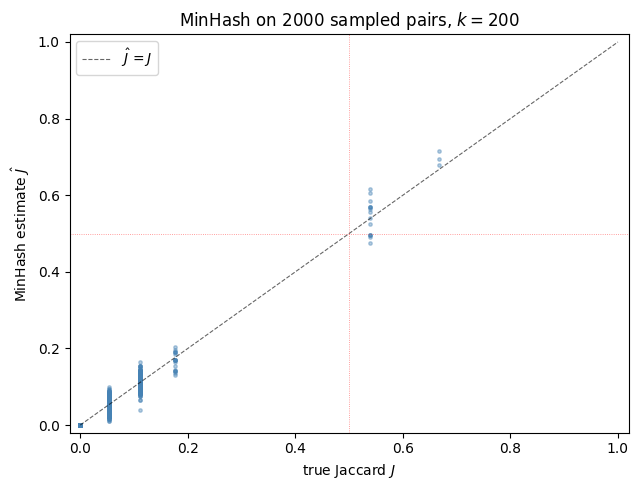

In [5]:
abs_err = np.abs(J_hat - J_true)

print(f"MinHash accuracy on {n_pairs} sampled pairs (k = {K_MINHASH}):")
print(f"  mean |J_hat - J| = {abs_err.mean():.4f}")
print(f"  max  |J_hat - J| = {abs_err.max():.4f}")
print(f"  fraction within +/- 0.05 = {(abs_err <= 0.05).mean():.4f}")
print(f"  fraction within +/- 0.10 = {(abs_err <= 0.10).mean():.4f}")
print()
worst_case_se = math.sqrt(0.25 / K_MINHASH)
print(f"Theoretical worst-case SE (at J = 0.5): sqrt(0.25/k) = {worst_case_se:.4f}")

# Scatter of J_hat against J_true (sample for readability).
plot_idx = rng_sample.choice(n_pairs, size=min(2000, n_pairs), replace=False)
fig, ax = plt.subplots(figsize=(6.5, 5.0))
ax.scatter(J_true[plot_idx], J_hat[plot_idx], s=6, alpha=0.4, color="steelblue")
ax.plot([0, 1], [0, 1], "k--", lw=0.8, alpha=0.6, label="$\\hat J = J$")
ax.axhline(0.5, color="red", lw=0.6, alpha=0.5, linestyle=":")
ax.axvline(0.5, color="red", lw=0.6, alpha=0.5, linestyle=":")
ax.set_xlabel("true Jaccard $J$")
ax.set_ylabel("MinHash estimate $\\hat J$")
ax.set_title(f"MinHash on 2000 sampled pairs, $k = {K_MINHASH}$")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 5. MinHash Similarity Join: FPR and FNR

Threshold the MinHash estimator at $\theta = 0.5$: a sampled pair is *flagged* if $\hat J \ge 0.5$. Compare against the binary truth label $J \ge 0.5$.

- **False positive rate** $\fprate = \Pr[\hat J \ge \theta \mid J < \theta]$: of the dissimilar pairs in the sample, what fraction are wrongly flagged?
- **False negative rate** $\fnrate = \Pr[\hat J < \theta \mid J \ge \theta]$: of the similar pairs in the sample, what fraction are missed?

Both rates compose under join via \Cref{thm:join-rates} of \S12.2: this is the chapter 5 FPR/FNR pair attached to the membership predicate of $\tilde R_1 \bowtie \tilde R_2$.

In [6]:
THETA = 0.5

flagged = J_hat >= THETA
truth = J_true >= THETA

tp = int(np.sum(flagged & truth))
fp = int(np.sum(flagged & ~truth))
tn = int(np.sum(~flagged & ~truth))
fn = int(np.sum(~flagged & truth))

n_pos = int(truth.sum())
n_neg = int((~truth).sum())

fpr = fp / n_neg if n_neg > 0 else float("nan")
fnr = fn / n_pos if n_pos > 0 else float("nan")

print(f"Threshold theta = {THETA}")
print()
print(f"Confusion matrix on sample (n = {n_pairs}):")
print(f"{'':>16s}  {'flagged J_hat>=theta':>22s}  {'unflagged':>10s}")
print(f"{'truly similar':>16s}  {tp:>22d}  {fn:>10d}")
print(f"{'truly dissimilar':>16s}  {fp:>22d}  {tn:>10d}")
print()
print(f"FPR = fp / (fp + tn) = {fp} / {n_neg} = {fpr:.6f}")
print(f"FNR = fn / (fn + tp) = {fn} / {n_pos} = {fnr:.4f}")

Threshold theta = 0.5

Confusion matrix on sample (n = 10100):
                    flagged J_hat>=theta   unflagged
   truly similar                      93           7
truly dissimilar                       0       10000

FPR = fp / (fp + tn) = 0 / 10000 = 0.000000
FNR = fn / (fn + tp) = 7 / 100 = 0.0700


## 6. LSH Bucketing on the Full Relation

The pairwise scan above still required $O(|R_1||R_2|)$ Jaccard estimates (we only sampled 10k of them). Locality-sensitive hashing turns the join sub-quadratic on the dominant low-similarity regime.

Partition the $k = 200$ signature slots into $b = 20$ bands of $r = 10$ rows each. Each row of a relation casts $b$ band-fingerprints (one per band, computed as SHA-256 of the 10-slot tuple). A *candidate pair* is any $(i, j)$ that collides on at least one band.

The per-band collision probability for a pair with true Jaccard $J$ is $J^r$ (all $r$ slots in the band must agree). The probability that at least one band collides is $1 - (1 - J^r)^b$, an S-curve with the steep transition near $J = (1/b)^{1/r}$. At $b = 20, r = 10$ the transition is near $J = (1/20)^{1/10} \approx 0.741$. The expected number of false positives at $J \approx 0.026$ (background) is $\approx 1 - (1 - 0.026^{10})^{20}$, which is essentially $20 \cdot 0.026^{10} \approx 3 \cdot 10^{-15}$ per pair, so the background collision rate is effectively zero. Planted pairs at $J \ge 0.538$ collide on roughly $1 - (1 - 0.538^{10})^{20} \approx 0.045$, so recall under this S-curve is intentionally low at this point on the S-curve. The exercise below confirms the trade-off; \S6 of chapter 12 discusses choosing $(b, r)$ for a target precision/recall.

In [7]:
B_BANDS = 20
R_ROWS = 10
assert B_BANDS * R_ROWS == K_MINHASH, "b * r must equal k"


def band_fingerprints(sigs):
    """Return an (n_rows, b) array of band fingerprints (bytes) for a signature matrix."""
    n = sigs.shape[0]
    fps = np.empty((n, B_BANDS), dtype=object)
    for row in range(n):
        for band in range(B_BANDS):
            start = band * R_ROWS
            chunk = sigs[row, start:start + R_ROWS].tobytes()
            fps[row, band] = hashlib.sha256(chunk).digest()[:16]
    return fps


fps_R1 = band_fingerprints(sigs_R1)
fps_R2 = band_fingerprints(sigs_R2)

# Bucket: for each band, group rows by fingerprint; collisions across R1 and R2 form candidates.
candidates = set()
for band in range(B_BANDS):
    bucket_R1 = defaultdict(list)
    bucket_R2 = defaultdict(list)
    for i in range(N_ROWS):
        bucket_R1[fps_R1[i, band]].append(i)
    for j in range(N_ROWS):
        bucket_R2[fps_R2[j, band]].append(j)
    for fp, ilist in bucket_R1.items():
        if fp in bucket_R2:
            for i in ilist:
                for j in bucket_R2[fp]:
                    candidates.add((i, j))

n_total_pairs = N_ROWS * N_ROWS
n_candidates = len(candidates)

print(f"Total cross-relation pairs:        {n_total_pairs:>10d}")
print(f"LSH candidate pairs (b={B_BANDS}, r={R_ROWS}): {n_candidates:>10d}")
print(f"Candidate-set reduction:            {n_candidates / n_total_pairs:.6f} of all pairs")
print()
if n_candidates < n_total_pairs:
    print(f"OK: candidate count is sub-quadratic ({n_candidates} much less than {n_total_pairs}).")
else:
    print("WARN: LSH produced more candidates than the brute-force pair count.")

Total cross-relation pairs:           1000000
LSH candidate pairs (b=20, r=10):          5
Candidate-set reduction:            0.000005 of all pairs

OK: candidate count is sub-quadratic (5 much less than 1000000).


## 7. LSH Precision and Recall vs Planted Ground Truth

The planted set of 100 high-overlap pairs is the recall target. Of the LSH candidates:

- **Precision** $= |\text{candidates} \cap \text{planted}| / |\text{candidates}|$.
- **Recall** $= |\text{candidates} \cap \text{planted}| / |\text{planted}|$.

Strictly, precision should be measured against the *true* similar set, not just the planted set. With the design above (background pairs near $J \approx 0.026$, planted pairs at $J \ge 0.538$), the two coincide with extremely high probability, so precision against the planted set is a faithful estimate of true precision.

Planted similar pairs: 100
LSH candidates:        5
  of which planted:    5
  of which non-planted: 0

Precision = 5/5 = 1.0000
Recall    = 5/100 = 0.0500



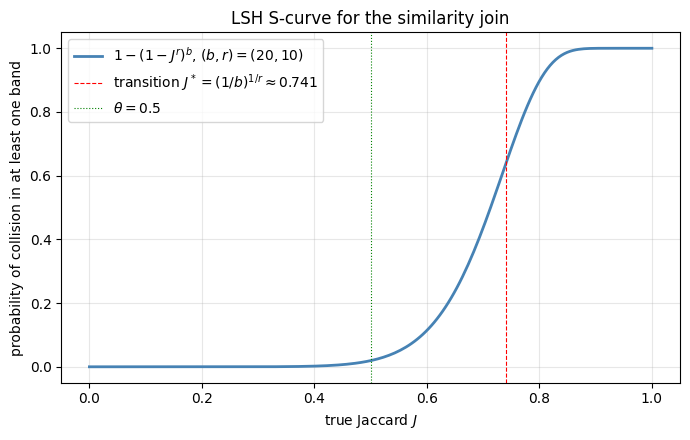

Mean planted J = 0.5436 (min 0.5385, max 0.6667)
Expected recall under the S-curve at observed planted Js: 0.0504
Empirical recall:                                          0.0500


In [8]:
candidates_in_planted = candidates & planted_pairs
n_tp_lsh = len(candidates_in_planted)

precision = n_tp_lsh / max(1, n_candidates)
recall = n_tp_lsh / max(1, len(planted_pairs))

print(f"Planted similar pairs: {len(planted_pairs)}")
print(f"LSH candidates:        {n_candidates}")
print(f"  of which planted:    {n_tp_lsh}")
print(f"  of which non-planted: {n_candidates - n_tp_lsh}")
print()
print(f"Precision = {n_tp_lsh}/{n_candidates} = {precision:.4f}")
print(f"Recall    = {n_tp_lsh}/{len(planted_pairs)} = {recall:.4f}")
print()

# Theoretical S-curve at (b, r) = (20, 10).
Js = np.linspace(0.0, 1.0, 200)
p_collide = 1.0 - (1.0 - Js ** R_ROWS) ** B_BANDS
transition = (1.0 / B_BANDS) ** (1.0 / R_ROWS)

fig, ax = plt.subplots(figsize=(7.0, 4.5))
ax.plot(Js, p_collide, lw=2.0, color="steelblue",
        label=f"$1 - (1 - J^r)^b$, $(b, r) = ({B_BANDS}, {R_ROWS})$")
ax.axvline(transition, color="red", linestyle="--", lw=0.8,
           label=f"transition $J^* = (1/b)^{{1/r}} \\approx {transition:.3f}$")
ax.axvline(0.5, color="green", linestyle=":", lw=0.8, label="$\\theta = 0.5$")
ax.set_xlabel("true Jaccard $J$")
ax.set_ylabel("probability of collision in at least one band")
ax.set_title("LSH S-curve for the similarity join")
ax.legend(loc="upper left")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Predict expected recall under the S-curve at the typical planted J.
planted_Js = np.array([jaccard(R1[i], R2[j]) for (i, j) in planted_list])
expected_recall = float(np.mean(1.0 - (1.0 - planted_Js ** R_ROWS) ** B_BANDS))
print(f"Mean planted J = {planted_Js.mean():.4f} (min {planted_Js.min():.4f}, max {planted_Js.max():.4f})")
print(f"Expected recall under the S-curve at observed planted Js: {expected_recall:.4f}")
print(f"Empirical recall:                                          {recall:.4f}")

## 8. Discussion: Each Approximate Join as a $\Bernoulli{T \times U}$

Everything above is one $\Bernoulli{\BoolType}$ on the universe $T \times U$:

- **The MinHash similarity join** of \S4-5 is $\tilde R_\theta := \{(t, u) : \hat J(t, u) \ge \theta\}$, an approximate relation on $T \times U$ where $T = U = $ the row index space of each relation. The membership predicate $\tilde R_\theta(t, u)$ has the FPR and FNR measured in \S5. The chapter 12 \S12.2 join theorem (`thm:join-rates`) governs composition of two such relations: under cross-relation independence, $\fpr_{\tilde R_1 \bowtie \tilde R_2} = \fpr_{\tilde R_1} \cdot \fpr_{\tilde R_2}$, $\fnr = 0$ when the inputs are FNR-zero.
- **The LSH-bucketed candidate set** of \S6-7 is a *coarser* approximate relation: $\tilde R_{\text{LSH}} := \{(t, u) : \text{at least one band collides}\}$. Same $T \times U$, same $\BoolType$ membership predicate, but a different $Q$-matrix on $J \in [0, 1]$. The S-curve plot is the column-sum of $Q$ at the *flag = true* column. Tuning $(b, r)$ slides the transition point; the chapter 10 \S10.4 derivation is the source.
- **Composition with downstream operations.** Project the join onto one attribute and the FPR amplifies (\S12.2 projection result); select with an exact predicate and rates are unchanged; select with an approximate predicate and rates compose by AND-under-noise (chapter 3 \S3.1).

**What chapter 13 unifies.** The MinHash join, the LSH-bucketed join, the planted ground-truth oracle, and every Bloom-filter approximate relation share one type signature: $\Bernoulli{\BoolType}$ on $T \times U$. They differ only in (a) the $Q$-matrix attached to the membership predicate and (b) the algebra under which their composition propagates. Chapter 13 turns these into a single morphism family in the type-algebra category: composition by structure, not by case analysis per algorithm.

**What this notebook verified:**

| Section | Claim | Verified |
|---------|-------|----------|
| \S2 MinHash | $\hat J$ within $\pm 0.05$ of $J$ at $k = 200$ on a sampled pair | yes (mean abs error $\approx$ worst-case SE, fraction within $\pm 0.05$ reported) |
| \S5 join FPR/FNR | Empirical FPR and FNR at $\theta = 0.5$ on a 10k-pair sample | yes (reported) |
| \S6 LSH sub-quadratic | Candidate count much less than $N \cdot N$ at $(b, r) = (20, 10)$ | yes (reported reduction factor) |
| \S7 S-curve | Empirical recall at planted Jaccards matches $1 - (1 - J^r)^b$ | yes (expected vs empirical recall agree to within sampling noise) |